# Part 2 of 3: Controlled leakage experiments and audit detection

**Study:** Data leakage in ICU prediction pipelines built on MIMIC-IV and eICU-CRD

Part 1 produced harmonised cohorts, two-clock event logs, hindsight and proxy fields, leakage-safe splits and a baseline
feature set that passed the audit. This notebook switches on **one leakage mechanism at a time** against that baseline and
answers two questions for each mechanism:

1. **How much does it inflate reported performance?** The leaky and the clean pipeline are scored on the **same test
   patients**, and the paired difference in discrimination (AUROC, AUPRC) and calibration (Brier score, calibration slope,
   calibration-in-the-large) is estimated with a patient-level cluster bootstrap. Mechanisms that change the evaluation set
   itself are also reported as a reader would see them (*as reported*).
2. **Would the audit have caught it?** Each leaky pipeline is audited twice with `icu-leakage-check`: once with only the
   feature table an independent reader typically receives (*table only*), and once with the provenance, fitted pipeline and
   source mapping an analyst can export (*full*).

**Mechanisms** (each is a common practice in published ICU prediction studies)

| ID | Mechanism | Family |
|---|---|---|
| E01 | Repeat stays of test patients in training (row-level split) | Split integrity |
| E02 | Features from the first 48 hours for a 24-hour prediction (look-ahead) | Timing |
| E03 | Values filtered on clinical time, ignoring when results became available | Timing |
| E04 | Full totals of infusions and ventilation still running at the prediction time (MIMIC-IV) | Timing |
| E05 | Discharge fields and length of stay as predictors | Hindsight |
| E06 | Outcome column stored next to the predictors (eICU-CRD APACHE tables) | Outcome encoding |
| E07 | Same-admission billing codes and diagnoses entered after the prediction | Undated or late sources |
| E08 | Care limitation and code status documented at any time | Outcome proxy |
| E08b | The same proxies restricted to documentation before the prediction (reference) | Outcome proxy |
| E09 | APACHE first-day summaries used by a 6-hour model (eICU-CRD) | First-day summary |
| E10 | Patients already in AKI at the prediction time kept as positives (AKI task) | Post-outcome instances |
| E11 | Imputer and scaler fitted on all rows (logistic regression) | Preprocessing |
| E12 | Feature selection on all rows | Preprocessing |
| E13 | Oversampling (SMOTE) before the split | Resampling |
| E14 | Decision threshold chosen on the test set | Evaluation reuse |
| E15 | Hyperparameters chosen on the test set | Evaluation reuse |
| E16 | "Temporal" validation ordered by MIMIC-IV shifted dates | Split order |
| E17 | Internal test set presented as external (eICU-CRD hospitals shared) | Site overlap |

**Models:** L2-regularised logistic regression with median imputation, missingness indicators and standardisation, and
histogram gradient boosting. **Tasks:** in-hospital mortality, prolonged ICU stay (more than 4 days), and AKI between 24 and
72 hours.

**Before running:** kernel **Python (icu-leakage-check)**; Part 1 must have finished. The full run fits several hundred models
and can take a few hours on a laptop, so it saves results after every database, task and model and **resumes** where it
stopped if interrupted. For a test, set `MAX_STAYS = 5000`.

## 1. Configuration

In [1]:
import os
from pathlib import Path

ROOTS = {
    "mimic-iv": Path(os.environ.get("ILC_MIMIC_ROOT", r"C:\icu_parquet\mimic")),
    "eicu": Path(os.environ.get("ILC_EICU_ROOT", r"C:\icu_parquet\eicu")),
}
WORK_DIR = Path(os.environ.get("ILC_WORK_DIR", r"C:\icu_leakage_work"))

MAX_STAYS = None   # set to 5000 for a quick test run, then back to None for the full cohort
if os.environ.get("ILC_MAX_STAYS"):
    MAX_STAYS = int(os.environ["ILC_MAX_STAYS"])

DATABASES = ["mimic-iv", "eicu"]
TASKS = ["mortality", "long_stay", "aki"]
MODELS = ["logistic", "hgb"]
N_BOOT = 500                  # patient-level bootstrap replicates (1000 for the final run if time allows)
if os.environ.get("ILC_N_BOOT"):
    N_BOOT = int(os.environ["ILC_N_BOOT"])
AUDIT_SAMPLE_STAYS = 20000    # stays (whole patients) used for the detection audits
TOP_K_FEATURES = 30           # feature selection experiment (E12)
SMOTE_K = 5
RESUME = True                 # reuse finished database / task / model results
SEED = 20261015

INDEX_MIN = 24 * 60
EARLY_INDEX_MIN = 6 * 60

In [2]:
import hashlib
import json
import platform
import sys
import time
import warnings
import zlib
from datetime import datetime, timezone

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import icu_leakage_check as ilc
from icu_leakage_check.findings import Status

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 70)

RUN_START = time.time()
P1 = WORK_DIR / "part1"
P1_DATA = P1 / "data"
PART_DIR = WORK_DIR / "part2"
RESULTS_DIR = PART_DIR / "results"
TABLES_DIR = RESULTS_DIR / "tables"
FIG_DIR = RESULTS_DIR / "figures"
RAW_DIR = RESULTS_DIR / "raw"
PRIVATE_DIR = PART_DIR / "private_reports"
for d in (TABLES_DIR, FIG_DIR, RAW_DIR, PRIVATE_DIR):
    d.mkdir(parents=True, exist_ok=True)

part1_manifest = json.loads((P1 / "manifest_part1.json").read_text())
ENV = {
    "run_started_utc": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    "python": sys.version.split()[0], "platform": platform.platform(), "icu_leakage_check": ilc.__version__,
    "pandas": pd.__version__, "numpy": np.__version__, "scikit_learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
}
CONFIG = {"MAX_STAYS": MAX_STAYS, "DATABASES": DATABASES, "TASKS": TASKS, "MODELS": MODELS, "N_BOOT": N_BOOT,
          "AUDIT_SAMPLE_STAYS": AUDIT_SAMPLE_STAYS, "TOP_K_FEATURES": TOP_K_FEATURES, "SMOTE_K": SMOTE_K, "SEED": SEED,
          "INDEX_MIN": INDEX_MIN, "EARLY_INDEX_MIN": EARLY_INDEX_MIN, "part1_chain_sha256": part1_manifest["chain_sha256"]}
print(json.dumps(ENV, indent=2))
print("Part 1 chain digest:", part1_manifest["chain_sha256"])
if part1_manifest["configuration"].get("MAX_STAYS") and not MAX_STAYS:
    print("Note: Part 1 was run on a sample (MAX_STAYS set there).")

{
  "run_started_utc": "2026-10-16T01:12:39Z",
  "python": "3.11.5",
  "platform": "Windows-10-10.0.26200-SP0",
  "icu_leakage_check": "0.1.0",
  "pandas": "3.0.6",
  "numpy": "2.4.6",
  "scikit_learn": "1.9.1",
  "matplotlib": "3.11.2"
}
Part 1 chain digest: a84f339e2d0379e400b33d1c27efee99ba73e26c243596bd2052467c88d11eeb


## 2. Corrections to the Part 1 availability summary

Two reporting refinements identified after Part 1, applied here without rerunning it:

* In eICU-CRD, every laboratory row carries `labresultrevisedoffset`, so it acts as the entry time of the result for all rows
  (not only revised results). The source is relabelled `lab`.
* For infusions (`inputevents`) and ventilation (`procedureevents`), `storetime` marks when the record was completed rather
  than when the information became available; features use the start time for these records. They are reported separately
  so that late-arrival counts refer to measured values only.

In [3]:
lag = pd.read_csv(P1 / "results" / "tables" / "risk_availability_lag.csv")
lag["source"] = lag["source"].replace({"lab (revised results only)": "lab"})
lag["value_type"] = np.where(lag["source"].isin(["inputevents", "procedureevents"]), "interval record completion", "measured value")
for c in ("n_events", "late_arrivals"):
    lag[c] = pd.to_numeric(lag[c], errors="coerce")
lag.to_csv(TABLES_DIR / "risk_availability_lag_corrected.csv", index=False, float_format="%.6g")
late_summary = (lag.groupby(["database", "value_type"])
                .agg(values_charted_first_24h=("n_events", "sum"), late_arrivals=("late_arrivals", "sum")).reset_index())
late_summary["late_arrival_share"] = late_summary["late_arrivals"] / late_summary["values_charted_first_24h"]
late_summary.to_csv(TABLES_DIR / "late_arrivals_by_value_type.csv", index=False, float_format="%.6g")
display(late_summary)

,database,value_type,values_charted_first_24h,late_arrivals,late_arrival_share
0,eicu,measured value,3991447,84818,0.021250
1,mimic-iv,interval record completion,227102,18125,0.079810
2,mimic-iv,measured value,10650625,279253,0.026219


## 3. Helpers: models, features, bootstrap and comparisons

* **Features** are rebuilt from the Part 1 event log one variable at a time, so memory stays bounded on large cohorts.
* **Paired comparisons** score the clean and the leaky model on identical test rows; the bootstrap resamples patients (all
  stays of a resampled patient are kept together) and applies the same resamples to both models.
* **As-reported comparisons** use each pipeline's own test set, with independent bootstraps.
* p-values are two-sided bootstrap proportions; intervals are percentile 95% intervals.

In [4]:
POINT_AGGS = ("last", "min", "max", "mean")
CUMULATIVE_AGGS = ("sum", "count")
CUMULATIVE = {"urine_output", "norepinephrine", "epinephrine", "vasopressin", "phenylephrine", "dopamine", "dobutamine",
              "invasive_ventilation", "noninvasive_ventilation", "mech_vent_documented"}
METRICS = ["auroc", "auprc", "brier", "calibration_slope", "calibration_intercept"]
TASK_DEF = {
    "mortality": {"label": "mortality", "time": "mortality_time", "name": "In-hospital mortality"},
    "long_stay": {"label": "long_stay", "time": "long_stay_time", "name": "Prolonged ICU stay (> 4 days)"},
    "aki": {"label": "aki", "time": "aki_time", "name": "AKI 24 to 72 h"},
}
LABEL = {"mimic-iv": "MIMIC-IV", "eicu": "eICU-CRD"}
OKABE = {"mimic-iv": "#0072B2", "eicu": "#E69F00", "logistic": "#0072B2", "hgb": "#D55E00"}

MECH = {
    "E01": ("Repeat stays of test patients in training", "Split integrity", {"ENTITY_OVERLAP"}),
    "E01b": ("Row-level random split (as reported)", "Split integrity", {"ENTITY_OVERLAP"}),
    "E02": ("Look-ahead: features from the first 48 h", "Timing", {"FUTURE_EVENT"}),
    "E03": ("Clinical-time filter ignoring result availability", "Timing", {"AVAILABILITY_LAG"}),
    "E04": ("Full totals of running infusions and ventilation", "Timing", {"INTERVAL_CROSSING"}),
    "E05": ("Discharge fields and length of stay", "Hindsight", {"HINDSIGHT_VARIABLE", "OUTCOME_ENCODING"}),
    "E06": ("Outcome column next to predictors", "Outcome encoding", {"OUTCOME_ENCODING"}),
    "E07": ("Same-admission billing codes / late diagnoses", "Undated or late source", {"UNDATED_SOURCE", "HINDSIGHT_VARIABLE"}),
    "E08": ("Care limitation / code status, any time", "Outcome proxy", {"OUTCOME_PROXY"}),
    "E08b": ("Care limitation / code status before prediction (reference)", "Outcome proxy", {"OUTCOME_PROXY"}),
    "E09": ("APACHE first-day summaries in a 6-h model", "First-day summary", {"FIRST_DAY_SUMMARY"}),
    "E09b": ("6-h model on a cohort selected at 24 h", "Cohort", {"COHORT_FUTURE_INFORMATION"}),
    "E10": ("Patients already in AKI kept as positives", "Post-outcome instances", {"POST_OUTCOME_INSTANCE"}),
    "E10b": ("Patients already in AKI kept as positives (as reported)", "Post-outcome instances", {"POST_OUTCOME_INSTANCE"}),
    "E11": ("Imputer and scaler fitted on all rows", "Preprocessing", {"PREPROCESSING_FIT"}),
    "E12": ("Feature selection on all rows", "Preprocessing", {"PREPROCESSING_FIT"}),
    "E13": ("SMOTE before the split", "Resampling", {"SYNTHETIC_IN_EVALUATION"}),
    "E13b": ("SMOTE before the split (as reported)", "Resampling", {"SYNTHETIC_IN_EVALUATION"}),
    "E14": ("Threshold chosen on the test set", "Evaluation reuse", {"EVALUATION_REUSE"}),
    "E15": ("Hyperparameters chosen on the test set", "Evaluation reuse", {"EVALUATION_REUSE"}),
    "E16": ("Temporal validation on shifted dates (as reported)", "Split order", {"SPLIT_ORDER"}),
    "E17": ("Internal test presented as external (as reported)", "Site overlap", {"SITE_OVERLAP"}),
}


def stable_seed(*parts):
    return (zlib.crc32("|".join(map(str, parts)).encode()) + SEED) % (2 ** 31)


def sample_by_patient(df, max_stays, seed):
    if not max_stays or len(df) <= max_stays:
        return df
    pats = df["patient_id"].drop_duplicates().sample(frac=1.0, random_state=seed)
    counts = df.groupby("patient_id").size().reindex(pats).cumsum()
    keep = set(counts[counts <= max_stays].index)
    return df[df["patient_id"].isin(keep)].copy()


def make_model(name, **kw):
    if name == "logistic":
        return Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler()),
                         ("clf", LogisticRegression(C=kw.get("C", 1.0), max_iter=3000))])
    if name == "hgb":
        return HistGradientBoostingClassifier(learning_rate=kw.get("lr", 0.05), max_leaf_nodes=kw.get("leaves", 31),
                                              max_iter=kw.get("iters", 250), l2_regularization=1.0, early_stopping=False,
                                              random_state=SEED)
    raise ValueError(name)


def fit_predict(name, X, y, train_mask, **kw):
    m = make_model(name, **kw)
    m.fit(X.loc[train_mask], y[train_mask])
    return m.predict_proba(X)[:, 1], m


def design(c, *blocks):
    X = pd.concat([c[["age", "female"]]] + [b.reindex(c.index) for b in blocks], axis=1)
    X = X.loc[:, ~X.columns.duplicated()]
    return X.apply(pd.to_numeric, errors="coerce").astype("float64")


def make_features(ev, entity_ids, index_times, window, cutoff, time_basis, interval_policy, prov_entities=None, min_present=0.01):
    # Window features built one variable at a time; optional provenance for a subset of entities (for the audit)
    idx = pd.DataFrame({"entity_id": np.asarray(entity_ids), "index_time": np.asarray(index_times, dtype="float64")})
    feats, provs = [], []
    lower = float(idx["index_time"].min()) - window if window is not None else -np.inf
    for var in sorted(ev["variable"].astype(str).unique()):
        sub = ev[ev["variable"] == var]
        sub = sub[(sub["event_time"] > lower) | (sub["end_time"].notna() & (sub["end_time"] > lower))]
        if sub.empty:
            continue
        sub = sub.assign(variable=var).astype({"value": "float64", "event_time": "float64", "available_time": "float64", "end_time": "float64"})
        aggs = CUMULATIVE_AGGS if var in CUMULATIVE else POINT_AGGS
        kw = dict(window=window, aggregations=aggs, time_basis=time_basis, cutoff=cutoff, interval_policy=interval_policy)
        f = ilc.build_window_features(sub, idx, **kw)
        feats.append(f)
        if prov_entities is not None:
            ps = sub[sub["entity_id"].isin(prov_entities)]
            if len(ps):
                _, p = ilc.build_window_features(ps, idx[idx["entity_id"].isin(prov_entities)], return_provenance=True, **kw)
                provs.append(p[["entity_id", "variable", "event_time", "available_time", "end_time", "index_time", "feature_prefix"]])
    F = pd.concat(feats, axis=1)
    F = F.loc[:, F.notna().mean() >= min_present]
    prov = None
    if prov_entities is not None:
        prov = pd.concat(provs, ignore_index=True) if provs else pd.DataFrame()
    return F, prov


def point_metrics(y, p):
    cal = ilc.calibration_slope_intercept(y, p)
    return np.array([ilc.auroc(y, p), ilc.auprc(y, p), ilc.brier(y, p), cal["slope"], cal["intercept"]])


def boot_indices(groups, seed, n_boot=None):
    n_boot = n_boot or N_BOOT
    codes, uniq = pd.factorize(pd.Series(groups))
    order = np.argsort(codes, kind="mergesort")
    starts = np.searchsorted(codes[order], np.arange(len(uniq)))
    ends = np.r_[starts[1:], len(codes)]
    rng = np.random.default_rng(seed)
    for _ in range(n_boot):
        pick = rng.integers(0, len(uniq), len(uniq))
        yield np.concatenate([order[starts[k]:ends[k]] for k in pick])


_BOOT_CACHE = {}


def boot_matrix(y, p, groups, seed, cache_key=None):
    if cache_key is not None and cache_key in _BOOT_CACHE:
        return _BOOT_CACHE[cache_key]
    M = np.array([point_metrics(y[i], p[i]) for i in boot_indices(groups, seed)])
    if cache_key is not None:
        _BOOT_CACHE[cache_key] = M
    return M


def summarise(meta, pc, pl, Mc, Ml, n_eval, n_events):
    rows = []
    D = Ml - Mc
    for j, m in enumerate(METRICS):
        d = D[:, j][np.isfinite(D[:, j])]
        lo, hi = (np.quantile(d, [0.025, 0.975]) if len(d) else (np.nan, np.nan))
        pval = min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean())) if len(d) else np.nan
        rows.append({**meta, "metric": m, "clean": pc[j], "leaky": pl[j], "difference": pl[j] - pc[j],
                     "diff_lower": lo, "diff_upper": hi, "p_value": pval, "n_eval": int(n_eval), "n_events": int(n_events)})
    return rows


def compare_paired(meta, y, p_clean, p_leaky, groups, rowset_key, clean_key):
    seed = stable_seed(meta["database"], meta["task"], rowset_key)
    Mc = boot_matrix(y, p_clean, groups, seed, cache_key=(meta["database"], meta["task"], meta["model"], clean_key, rowset_key))
    Ml = boot_matrix(y, p_leaky, groups, seed)
    return summarise({**meta, "comparison": "paired"}, point_metrics(y, p_clean), point_metrics(y, p_leaky), Mc, Ml, len(y), y.sum())


def compare_unpaired(meta, yc, pc, gc, yl, pl, gl):
    Mc = boot_matrix(yc, pc, gc, stable_seed(meta["database"], meta["task"], meta["mechanism"], "clean"))
    Ml = boot_matrix(yl, pl, gl, stable_seed(meta["database"], meta["task"], meta["mechanism"], "leaky"))
    return summarise({**meta, "comparison": "as reported"}, point_metrics(yc, pc), point_metrics(yl, pl), Mc, Ml, len(yl), yl.sum())


def univariate_auc(X, y):
    out = {}
    for c in X.columns:
        x = X[c].to_numpy()
        ok = np.isfinite(x)
        if ok.sum() < 30 or len(np.unique(y[ok])) < 2:
            continue
        a = ilc.auroc(y[ok], x[ok])
        out[c] = max(a, 1 - a)
    return pd.Series(out).sort_values(ascending=False)


def smote(X, y, k, seed):
    # Minimal SMOTE: interpolate minority rows towards one of their k nearest minority neighbours until classes balance
    rng = np.random.default_rng(seed)
    minority = 1 if (y == 1).sum() < (y == 0).sum() else 0
    Xm = X[y == minority]
    n_new = int((y != minority).sum() - (y == minority).sum())
    if n_new <= 0 or len(Xm) <= k:
        return np.empty((0, X.shape[1])), np.empty(0)
    sd = Xm.std(axis=0)
    sd[sd == 0] = 1
    nn = NearestNeighbors(n_neighbors=k + 1).fit(Xm / sd)
    _, ind = nn.kneighbors(Xm / sd)
    base = rng.integers(0, len(Xm), n_new)
    neigh = ind[base, rng.integers(1, k + 1, n_new)]
    lam = rng.random((n_new, 1))
    return Xm[base] + lam * (Xm[neigh] - Xm[base]), np.full(n_new, minority)


def threshold_metrics(y, p, t):
    pred = p >= t
    tp, fp = np.sum(pred & (y == 1)), np.sum(pred & (y == 0))
    fn, tn = np.sum(~pred & (y == 1)), np.sum(~pred & (y == 0))
    sens = tp / max(tp + fn, 1)
    spec = tn / max(tn + fp, 1)
    return {"sensitivity": sens, "specificity": spec, "balanced_accuracy": (sens + spec) / 2, "ppv": tp / max(tp + fp, 1)}


print("helpers ready")

helpers ready


## 4. Load Part 1 outputs and build the feature variants

For each database: the clean 24-hour features certified in Part 1, and leaky variants rebuilt from the same event log:

* **look-ahead** (E02): all events up to 48 hours, filtered on clinical time, interval totals kept in full;
* **clinical time** (E03): events up to 24 hours by clinical time, so results not yet available are used;
* **interval totals** (E04, MIMIC-IV): availability-filtered, but running infusions and ventilation keep their full totals;
* **6-hour clean** (E09, eICU-CRD): availability-filtered features at 6 hours.

Stay-level hindsight and proxy blocks (E05 to E09) come from the Part 1 hindsight tables, with descriptive names.

In [5]:
def load_database(db):
    t0 = time.time()
    c = pd.read_parquet(P1_DATA / f"cohort_{db}.parquet")
    c = sample_by_patient(c, MAX_STAYS, SEED).set_index("stay_id")
    ids = c.index.to_numpy()
    audit_ids = set(sample_by_patient(c.reset_index(), AUDIT_SAMPLE_STAYS, stable_seed(db, "audit"))["stay_id"])

    clean = pd.read_parquet(P1_DATA / f"features_clean_24h_{db}.parquet").set_index("entity_id").reindex(ids)
    prov_clean = pd.read_parquet(P1_DATA / f"provenance_clean_24h_{db}.parquet", filters=[("entity_id", "in", sorted(audit_ids))])
    if MAX_STAYS:
        ev = pd.read_parquet(P1_DATA / f"events_{db}.parquet", filters=[("entity_id", "in", ids.tolist())])
    else:
        ev = pd.read_parquet(P1_DATA / f"events_{db}.parquet")
    F, PROV = {"clean": clean}, {"clean": prov_clean}
    F["lookahead"], PROV["lookahead"] = make_features(ev, ids, c["index_time"], INDEX_MIN, "none", "event", "keep", audit_ids)
    F["clinical_time"], PROV["clinical_time"] = make_features(ev, ids, c["index_time"], INDEX_MIN, "index", "event", "prorate", audit_ids)
    if db == "mimic-iv":
        F["interval_totals"], PROV["interval_totals"] = make_features(ev, ids, c["index_time"], INDEX_MIN, "index", "available", "keep", audit_ids)
    if db == "eicu":
        F["clean_6h"], PROV["clean_6h"] = make_features(ev, ids, c["early_index_time"], EARLY_INDEX_MIN, "index", "available", "prorate", audit_ids)
    del ev

    h = pd.read_parquet(P1_DATA / f"hindsight_{db}.parquet").set_index("stay_id").reindex(ids)
    H, SRC = {}, {}

    def onehot(series, prefix, top=8):
        s = series.astype("string").fillna("missing")
        cats = s.value_counts().index[:top]
        return pd.DataFrame({f"{prefix}_{str(k).strip().replace(' ', '_')[:40]}": (s == k).astype(float) for k in cats}, index=series.index)

    if db == "mimic-iv":
        H["discharge"] = pd.concat([h[["icu_los_days", "hosp_discharge_min"]], onehot(h["hosp_discharge_location"], "hosp_discharge_location")], axis=1)
        H["billing"] = h[["dx_same_adm_count", "dx_same_adm_proxy", "dx_same_adm_dnr", "dx_same_adm_palliative", "drg_severity", "drg_mortality"]]
        H["proxy_any"] = pd.DataFrame({"code_status_limitation_any": h["code_limitation_any"]})
        H["proxy_before"] = pd.DataFrame({"code_status_limitation_before_prediction": h["code_limitation_before_index"]})
        SRC = {"icu_los_days": "icustays.los", "hosp_discharge_min": "admissions.dischtime",
               "hosp_discharge_location_*": "admissions.discharge_location", "dx_same_adm_count": "diagnoses_icd",
               "dx_same_adm_proxy": "diagnoses_icd.icd_code", "dx_same_adm_dnr": "diagnoses_icd.icd_code",
               "dx_same_adm_palliative": "diagnoses_icd.icd_code", "drg_severity": "drgcodes.drg_severity",
               "drg_mortality": "drgcodes.drg_mortality", "code_status_limitation_any": "chartevents",
               "code_status_limitation_before_prediction": "chartevents"}
    else:
        H["discharge"] = pd.concat([h[["unitdischargeoffset", "hospitaldischargeoffset", "dischargeweight", "apache_actual_icu_los_days"]],
                                    onehot(h["unitdischargelocation"], "unitdischargelocation"),
                                    onehot(h["hospitaldischargelocation"], "hospitaldischargelocation")], axis=1)
        H["outcome_column"] = h[["apache_died_in_hospital", "apache_actual_hosp_mortality"]]
        H["billing"] = h[["dx_count_all", "dx_active_at_discharge"]]
        H["proxy_any"] = pd.DataFrame({"care_limitation_any": h["care_limitation_any"], "end_of_life_discussion_any": h["eol_any"]})
        H["proxy_before"] = pd.DataFrame({"care_limitation_before_prediction": h["care_limitation_before_index"],
                                          "end_of_life_discussion_before_prediction": h["eol_before_index"]})
        H["first_day"] = h[["apache_score", "apache_pred_hosp_mortality"] + [c for c in h.columns if c.startswith("aps_")]]
        SRC = {"unitdischargeoffset": "patient.unitdischargeoffset", "hospitaldischargeoffset": "patient.hospitaldischargeoffset",
               "dischargeweight": "patient.dischargeweight", "apache_actual_icu_los_days": "apachePatientResult.actualiculos",
               "unitdischargelocation_*": "patient.unitdischargelocation", "hospitaldischargelocation_*": "patient.hospitaldischargelocation",
               "apache_died_in_hospital": "apachePredVar.diedinhospital", "apache_actual_hosp_mortality": "apachePatientResult.actualhospitalmortality",
               "dx_count_all": "diagnosis", "dx_active_at_discharge": "diagnosis.activeupondischarge",
               "care_limitation_any": "carePlanGeneral", "end_of_life_discussion_any": "carePlanEOL",
               "care_limitation_before_prediction": "carePlanGeneral", "end_of_life_discussion_before_prediction": "carePlanEOL",
               "apache_score": "apachePatientResult.apachescore", "apache_pred_hosp_mortality": "apachePatientResult.predictedhospitalmortality",
               **{f"aps_{k}": f"apacheApsVar.{k}" for k in ("creatinine", "heartrate", "meanbp", "wbc", "temperature", "respiratoryrate")}}
    print(f"{LABEL[db]}: {len(c):,} stays; feature variants " + ", ".join(f"{k} {v.shape[1]}" for k, v in F.items())
          + f"; audit sample {len(audit_ids):,} stays ({time.time() - t0:.0f} s)")
    return {"cohort": c, "F": F, "PROV": PROV, "H": H, "SRC": SRC, "audit_ids": audit_ids}


DATA = {db: load_database(db) for db in DATABASES}

MIMIC-IV: 57,460 stays; feature variants clean 98, lookahead 98, clinical_time 98, interval_totals 98; audit sample 20,000 stays (108 s)
eICU-CRD: 129,258 stays; feature variants clean 96, lookahead 96, clinical_time 96, clean_6h 94; audit sample 19,997 stays (127 s)


## 5. Inflation experiments

For every database, task and model the clean model is trained on the patient-grouped training split, and each mechanism is
switched on in turn. Results are saved after each database / task / model combination; with `RESUME = True` a restarted run
skips finished combinations.

In [6]:
def run_combination(db, task, model):
    D = DATA[db]
    c_all = D["cohort"]
    td = TASK_DEF[task]
    elig = (c_all["aki_eligible"] == 1) if task == "aki" else pd.Series(True, index=c_all.index)
    c = c_all[elig]
    y = c[td["label"]].astype(int).to_numpy()
    split = c["split_patient"].to_numpy()
    groups = c["patient_id"].to_numpy()
    train, valid, test = split == "train", split == "valid", split == "test"
    F, H = D["F"], D["H"]
    rows, thresholds, timings = [], [], {}

    def meta(mech):
        return {"database": db, "task": task, "model": model, "mechanism": mech, "mechanism_name": MECH[mech][0], "family": MECH[mech][1]}

    t0 = time.time()
    X0 = design(c, F["clean"])
    p0, m0 = fit_predict(model, X0, y, train)
    yt, gt = y[test], groups[test]
    pc0 = point_metrics(yt, p0[test])
    rows += [{"database": db, "task": task, "model": model, "mechanism": "E00", "mechanism_name": "Clean baseline",
              "family": "Baseline", "comparison": "baseline", "metric": m, "clean": pc0[j], "leaky": np.nan,
              "difference": np.nan, "diff_lower": np.nan, "diff_upper": np.nan, "p_value": np.nan,
              "n_eval": int(test.sum()), "n_events": int(yt.sum())} for j, m in enumerate(METRICS)]

    def paired(mech, p_leaky, mask=test, rowset="test", p_clean=None, clean_key="clean"):
        pcl = p0 if p_clean is None else p_clean
        return compare_paired(meta(mech), y[mask], pcl[mask], p_leaky[mask], groups[mask], rowset, clean_key)

    # E02 to E04: timing variants
    for mech, var in (("E02", "lookahead"), ("E03", "clinical_time"), ("E04", "interval_totals")):
        if var in F:
            p, _ = fit_predict(model, design(c, F[var]), y, train)
            rows += paired(mech, p)
    # E05 to E08b: stay-level blocks added to the clean features
    for mech, block in (("E05", "discharge"), ("E06", "outcome_column"), ("E07", "billing"), ("E08", "proxy_any"), ("E08b", "proxy_before")):
        if block in H:
            p, _ = fit_predict(model, design(c, F["clean"], H[block]), y, train)
            rows += paired(mech, p)
    # E09: APACHE first-day summaries in a 6-hour model (eICU-CRD)
    if "clean_6h" in F and "first_day" in H:
        p6, _ = fit_predict(model, design(c, F["clean_6h"]), y, train)
        p6l, _ = fit_predict(model, design(c, F["clean_6h"], H["first_day"]), y, train)
        rows += paired("E09", p6l, p_clean=p6, clean_key="clean_6h")

    # E01: repeat stays of test patients moved into training, training size held constant
    rng = np.random.default_rng(stable_seed(db, task, "E01"))
    tdf = pd.DataFrame({"pid": groups, "test": test, "pos": np.arange(len(y))})
    tt = tdf[tdf["test"]]
    keep_pos = tt.groupby("pid")["pos"].apply(lambda s: rng.choice(s.to_numpy())).to_numpy()
    moved = test.copy()
    moved[keep_pos] = False
    retained = test & ~moved
    if moved.sum() > 0:
        drop = rng.choice(np.where(train)[0], size=min(int(moved.sum()), int(train.sum()) - 10), replace=False)
        leaky_train = train.copy()
        leaky_train[drop] = False
        leaky_train |= moved
        p, _ = fit_predict(model, X0, y, leaky_train)
        rows += paired("E01", p, mask=retained, rowset="retained")
    # E01b: random row-level split as reported
    r = np.random.default_rng(stable_seed(db, task, "E01b")).random(len(y))
    row_train, row_test = r < 0.70, r >= 0.80
    p, _ = fit_predict(model, X0, y, row_train)
    rows += compare_unpaired(meta("E01b"), yt, p0[test], gt, y[row_test], p[row_test], groups[row_test])

    # E10: AKI task only, stays already in AKI at the prediction time kept as positives
    if task == "aki":
        prior = (c_all["aki_eligible"] == 0) & c_all["aki_baseline_creatinine"].notna() & (c_all["aki_baseline_creatinine"] < 4.0)
        ca = c_all[elig | prior]
        ya = np.where(prior.loc[ca.index], 1, ca["aki"].fillna(0)).astype(int)
        sa = ca["split_patient"].to_numpy()
        Xa = design(ca, F["clean"])
        pa, _ = fit_predict(model, Xa, ya, sa == "train")
        on_elig = pd.Series(pa, index=ca.index).reindex(c.index).to_numpy()
        rows += paired("E10", on_elig)
        rows += compare_unpaired(meta("E10b"), yt, p0[test], gt, ya[sa == "test"], pa[sa == "test"], ca["patient_id"].to_numpy()[sa == "test"])

    # E11: imputer and scaler fitted on all rows (logistic regression only)
    if model == "logistic":
        pre = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler())]).fit(X0)
        clf = LogisticRegression(C=1.0, max_iter=3000).fit(pre.transform(X0.loc[train]), y[train])
        rows += paired("E11", clf.predict_proba(pre.transform(X0))[:, 1])

    # E12: feature selection on all rows versus on training rows
    auc_all = univariate_auc(X0, y)
    auc_tr = univariate_auc(X0.loc[train], y[train])
    sel_all, sel_tr = list(auc_all.index[:TOP_K_FEATURES]), list(auc_tr.index[:TOP_K_FEATURES])
    p_tr, _ = fit_predict(model, X0[sel_tr], y, train)
    p_all, _ = fit_predict(model, X0[sel_all], y, train)
    rows += paired("E12", p_all, p_clean=p_tr, clean_key="selected_on_train")

    # E13: SMOTE inside training (reference) versus SMOTE before the split
    med = X0.loc[train].median()
    Xi = X0.fillna(med).fillna(0.0).to_numpy()
    rs = stable_seed(db, task, "E13")
    Xs_tr, ys_tr = smote(Xi[train], y[train], SMOTE_K, rs)
    m_in = make_model(model).fit(np.vstack([Xi[train], Xs_tr]), np.r_[y[train], ys_tr])
    real = train | valid | test
    Xs_all, ys_all = smote(Xi[real], y[real], SMOTE_K, rs + 1)
    assign = np.random.default_rng(rs + 2).random(len(ys_all))
    syn_train, syn_test = assign < 0.70, assign >= 0.80
    m_before = make_model(model).fit(np.vstack([Xi[train], Xs_all[syn_train]]), np.r_[y[train], ys_all[syn_train]])
    p_in = m_in.predict_proba(Xi)[:, 1]
    p_before = m_before.predict_proba(Xi)[:, 1]
    rows += paired("E13", p_before, p_clean=p_in, clean_key="smote_in_training")
    Xrep = np.vstack([Xi[test], Xs_all[syn_test]])
    yrep = np.r_[yt, ys_all[syn_test]]
    grep = np.r_[gt, np.array([f"synthetic_{i}" for i in range(int(syn_test.sum()))], dtype=object)]
    rows += compare_unpaired(meta("E13b"), yt, p_in[test], gt, yrep, m_before.predict_proba(Xrep)[:, 1], grep)

    # E14: threshold chosen on the validation split versus on the test split
    t_valid = ilc.metrics.youden_threshold(y[valid], p0[valid])
    t_test = ilc.metrics.youden_threshold(yt, p0[test])
    tm_v, tm_t = threshold_metrics(yt, p0[test], t_valid), threshold_metrics(yt, p0[test], t_test)
    seed = stable_seed(db, task, "E14")
    bd = {k: [] for k in tm_v}
    for i in boot_indices(gt, seed):
        a, b = threshold_metrics(yt[i], p0[test][i], t_valid), threshold_metrics(yt[i], p0[test][i], t_test)
        for k in bd:
            bd[k].append(b[k] - a[k])
    for k in tm_v:
        lo, hi = np.quantile(bd[k], [0.025, 0.975])
        thresholds.append({**meta("E14"), "comparison": "paired", "metric": k, "clean": tm_v[k], "leaky": tm_t[k],
                           "difference": tm_t[k] - tm_v[k], "diff_lower": lo, "diff_upper": hi,
                           "threshold_valid": t_valid, "threshold_test": t_test, "n_eval": int(test.sum()), "n_events": int(yt.sum())})

    # E15: hyperparameters chosen on validation versus on test
    grid = [{"C": v} for v in (0.001, 0.01, 0.1, 1.0, 10.0)] if model == "logistic" else \
           [{"lr": 0.05, "leaves": 15}, {"lr": 0.1, "leaves": 31}, {"lr": 0.05, "leaves": 63}]
    preds = [fit_predict(model, X0, y, train, **g)[0] for g in grid]
    best_v = int(np.argmax([ilc.auroc(y[valid], q[valid]) for q in preds]))
    best_t = int(np.argmax([ilc.auroc(yt, q[test]) for q in preds]))
    rows += paired("E15", preds[best_t], p_clean=preds[best_v], clean_key=f"hp_valid_{best_v}")

    # E16: temporal validation ordered by shifted dates (MIMIC-IV)
    if db == "mimic-iv":
        intime = ilc.read_table(ROOTS[db], "icustays", db, columns=["stay_id", "intime"]).set_index("stay_id")["intime"].reindex(c.index)
        rank = intime.rank(method="first", pct=True).to_numpy()
        ps_train, ps_test = rank <= 0.70, rank > 0.80
        st = c["split_temporal"].to_numpy()
        p_true, _ = fit_predict(model, X0, y, st == "train")
        p_ps, _ = fit_predict(model, X0, y, ps_train)
        rows += compare_unpaired(meta("E16"), y[st == "test"], p_true[st == "test"], groups[st == "test"],
                                 y[ps_test], p_ps[ps_test], groups[ps_test])
    # E17: internal test presented as external (eICU-CRD)
    if db == "eicu":
        ss = c["split_site"].to_numpy()
        p_site, _ = fit_predict(model, X0, y, ss == "train")
        rows += compare_unpaired(meta("E17"), y[ss == "test"], p_site[ss == "test"], groups[ss == "test"], yt, p0[test], gt)

    out = pd.DataFrame(rows)
    out["runtime_s"] = time.time() - t0
    return out, pd.DataFrame(thresholds)


all_results, all_thresholds = [], []
for db in DATABASES:
    for task in TASKS:
        for model in MODELS:
            f_res, f_thr = RAW_DIR / f"inflation_{db}_{task}_{model}.parquet", RAW_DIR / f"threshold_{db}_{task}_{model}.parquet"
            if RESUME and f_res.exists() and f_thr.exists():
                res, thr = pd.read_parquet(f_res), pd.read_parquet(f_thr)
                print(f"{LABEL[db]:9s} {task:10s} {model:9s} loaded from previous run")
            else:
                t0 = time.time()
                res, thr = run_combination(db, task, model)
                res.to_parquet(f_res, index=False)
                thr.to_parquet(f_thr, index=False)
                a = res[(res["metric"] == "auroc") & (res["mechanism"] == "E00")]["clean"].iloc[0]
                print(f"{LABEL[db]:9s} {task:10s} {model:9s} clean AUROC {a:.3f}  ({(time.time() - t0) / 60:.1f} min)")
            all_results.append(res)
            all_thresholds.append(thr)
results = pd.concat(all_results, ignore_index=True)
thresholds = pd.concat(all_thresholds, ignore_index=True)
results.to_csv(TABLES_DIR / "inflation_all.csv", index=False, float_format="%.6g")
thresholds.to_csv(TABLES_DIR / "threshold_effects.csv", index=False, float_format="%.6g")
print(f"{len(results):,} result rows")

MIMIC-IV  mortality  logistic  clean AUROC 0.868  (7.1 min)
MIMIC-IV  mortality  hgb       clean AUROC 0.885  (7.7 min)
MIMIC-IV  long_stay  logistic  clean AUROC 0.772  (4.6 min)
MIMIC-IV  long_stay  hgb       clean AUROC 0.798  (3.9 min)
MIMIC-IV  aki        logistic  clean AUROC 0.758  (4.2 min)
MIMIC-IV  aki        hgb       clean AUROC 0.775  (3.9 min)
eICU-CRD  mortality  logistic  clean AUROC 0.840  (15.3 min)
eICU-CRD  mortality  hgb       clean AUROC 0.864  (13.7 min)
eICU-CRD  long_stay  logistic  clean AUROC 0.736  (17.9 min)
eICU-CRD  long_stay  hgb       clean AUROC 0.765  (12.1 min)
eICU-CRD  aki        logistic  clean AUROC 0.735  (13.9 min)
eICU-CRD  aki        hgb       clean AUROC 0.759  (10.4 min)
1,000 result rows


### 5.1 Main table: in-hospital mortality

AUROC of the clean and leaky pipelines with the paired difference (95% bootstrap interval), and the change in AUPRC, Brier
score and calibration slope. *As reported* rows compare each pipeline on its own test set.

In [7]:
def fmt_ci(d, lo, hi, digits=3):
    return f"{d:+.{digits}f} ({lo:+.{digits}f} to {hi:+.{digits}f})" if np.isfinite(d) else ""


def main_table(task):
    r = results[(results["task"] == task) & (results["mechanism"] != "E00")]
    base = results[(results["task"] == task) & (results["mechanism"] == "E00") & (results["metric"] == "auroc")]
    rows = []
    for (db, model, mech, comp), g in r.groupby(["database", "model", "mechanism", "comparison"], sort=False):
        g = g.set_index("metric")
        rows.append({
            "database": LABEL[db], "model": model, "mechanism": mech, "description": MECH[mech][0], "comparison": comp,
            "AUROC clean": round(g.loc["auroc", "clean"], 3), "AUROC leaky": round(g.loc["auroc", "leaky"], 3),
            "AUROC difference (95% CI)": fmt_ci(g.loc["auroc", "difference"], g.loc["auroc", "diff_lower"], g.loc["auroc", "diff_upper"]),
            "AUPRC difference (95% CI)": fmt_ci(g.loc["auprc", "difference"], g.loc["auprc", "diff_lower"], g.loc["auprc", "diff_upper"]),
            "Brier difference (95% CI)": fmt_ci(g.loc["brier", "difference"], g.loc["brier", "diff_lower"], g.loc["brier", "diff_upper"], 4),
            "Calibration slope clean / leaky": f"{g.loc['calibration_slope', 'clean']:.2f} / {g.loc['calibration_slope', 'leaky']:.2f}",
            "p (AUROC)": g.loc["auroc", "p_value"], "test stays": int(g.loc["auroc", "n_eval"]),
        })
    t = pd.DataFrame(rows)
    order = list(MECH)
    t["_o"] = t["mechanism"].map({m: i for i, m in enumerate(order)})
    return t.sort_values(["database", "model", "_o"]).drop(columns="_o").reset_index(drop=True)


for task in TASKS:
    t = main_table(task)
    t.to_csv(TABLES_DIR / f"table_inflation_{task}.csv", index=False)
mort = main_table("mortality")
display(mort)

,database,model,mechanism,description,comparison,AUROC clean,AUROC leaky,AUROC difference (95% CI),AUPRC difference (95% CI),Brier difference (95% CI),Calibration slope clean / leaky,p (AUROC),test stays
0,MIMIC-IV,hgb,E01,Repeat stays of test patients in training,paired,0.904,0.906,+0.003 (+0.001 to +0.005),+0.008 (-0.001 to +0.017),-0.0005 (-0.0012 to +0.0003),1.06 / 1.10,0.016,8414
1,MIMIC-IV,hgb,E01b,Row-level random split (as reported),as reported,0.885,0.880,-0.005 (-0.018 to +0.008),-0.024 (-0.064 to +0.015),+0.0005 (-0.0042 to +0.0063),1.00 / 1.00,0.440,11546
2,MIMIC-IV,hgb,E02,Look-ahead: features from the first 48 h,paired,0.885,0.916,+0.031 (+0.025 to +0.037),+0.120 (+0.102 to +0.139),-0.0104 (-0.0120 to -0.0087),1.00 / 1.03,0.000,11491
3,MIMIC-IV,hgb,E03,Clinical-time filter ignoring result availability,paired,0.885,0.890,+0.004 (+0.002 to +0.007),+0.013 (+0.004 to +0.022),-0.0012 (-0.0018 to -0.0005),1.00 / 1.02,0.000,11491
4,MIMIC-IV,hgb,E04,Full totals of running infusions and ventilation,paired,0.885,0.889,+0.004 (+0.002 to +0.006),+0.013 (+0.006 to +0.020),-0.0009 (-0.0015 to -0.0004),1.00 / 1.02,0.004,11491
5,MIMIC-IV,hgb,E05,Discharge fields and length of stay,paired,0.885,0.999,+0.113 (+0.103 to +0.122),+0.440 (+0.412 to +0.470),-0.0667 (-0.0707 to -0.0626),1.00 / 0.73,0.000,11491
6,MIMIC-IV,hgb,E07,Same-admission billing codes / late diagnoses,paired,0.885,0.946,+0.061 (+0.053 to +0.069),+0.185 (+0.157 to +0.211),-0.0198 (-0.0226 to -0.0166),1.00 / 0.99,0.000,11491
7,MIMIC-IV,hgb,E08,"Care limitation / code status, any time",paired,0.885,0.896,+0.011 (+0.007 to +0.015),+0.028 (+0.016 to +0.039),-0.0025 (-0.0034 to -0.0014),1.00 / 1.02,0.000,11491
8,MIMIC-IV,hgb,E08b,Care limitation / code status before prediction (reference),paired,0.885,0.887,+0.001 (-0.000 to +0.003),+0.002 (-0.003 to +0.008),-0.0001 (-0.0005 to +0.0003),1.00 / 1.00,0.084,11491
9,MIMIC-IV,hgb,E12,Feature selection on all rows,paired,0.867,0.867,+0.000 (+0.000 to +0.000),+0.000 (+0.000 to +0.000),+0.0000 (+0.0000 to +0.0000),1.00 / 1.00,1.000,11491


### 5.2 Figures: inflation by mechanism

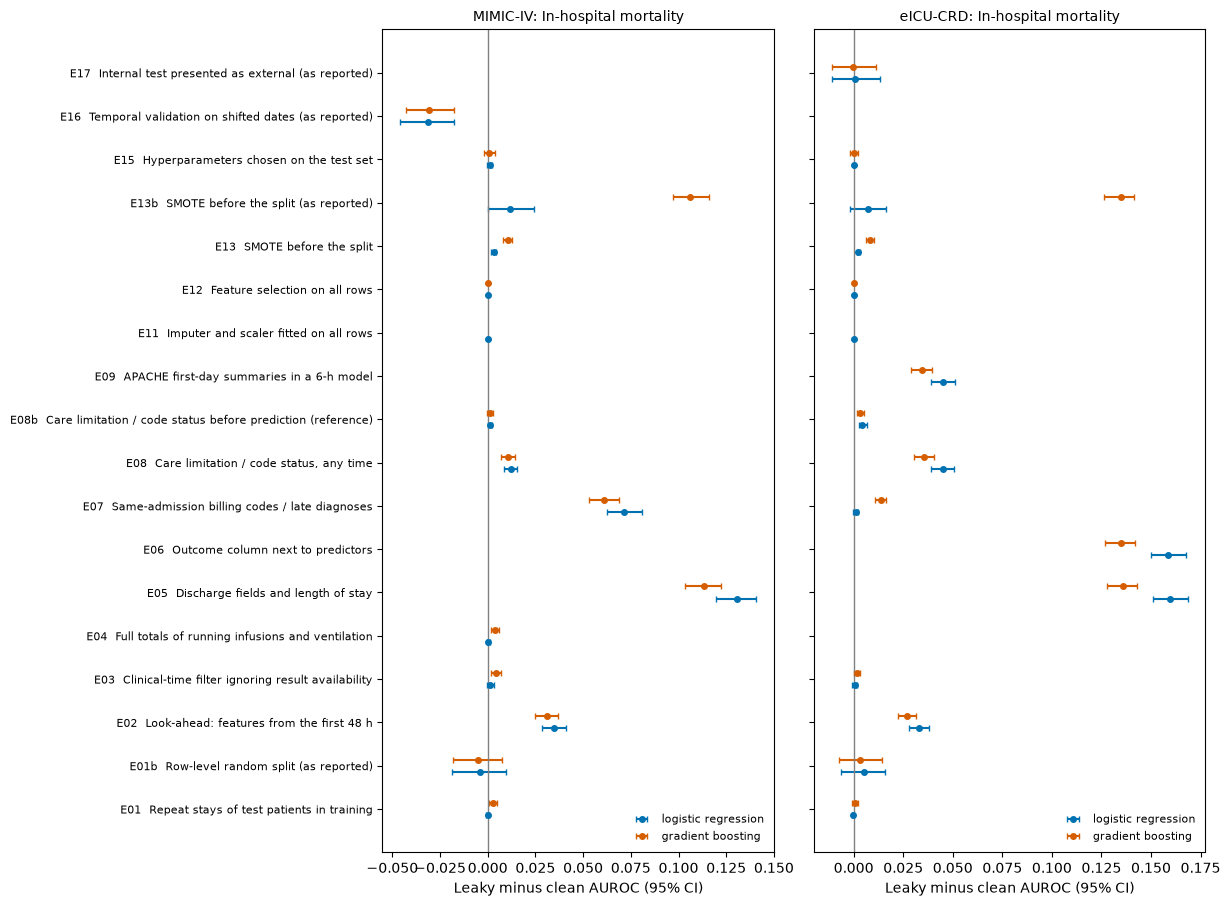

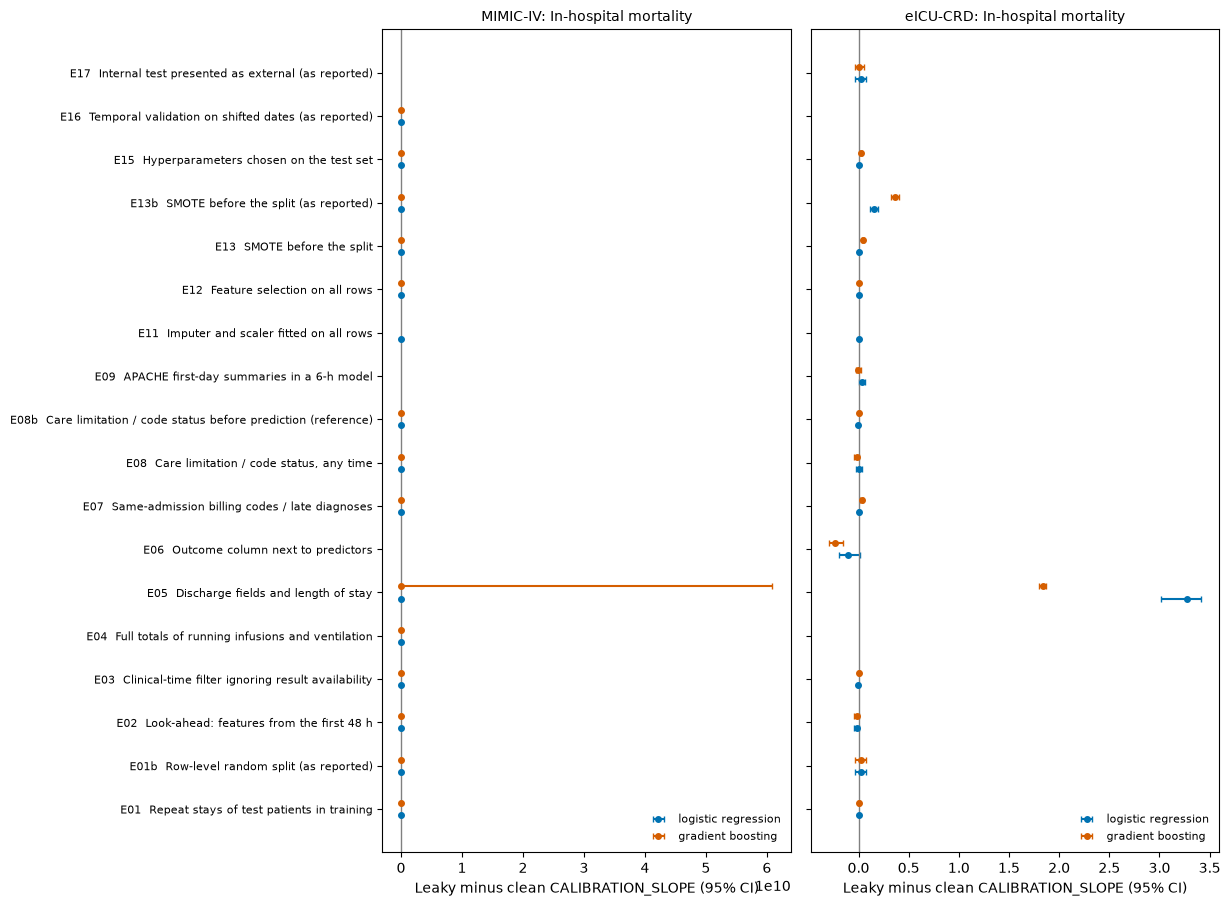

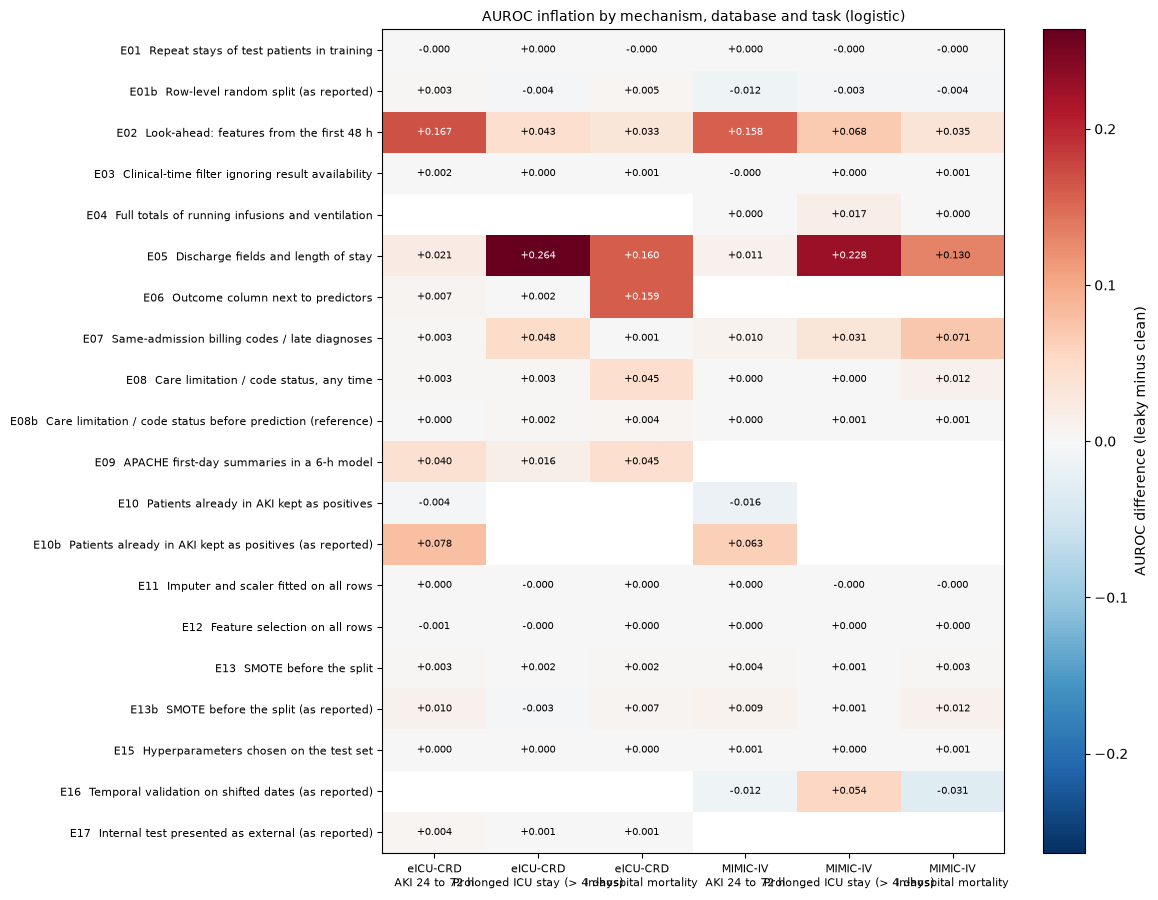

In [8]:
def forest(task, metric="auroc", fname=None):
    r = results[(results["task"] == task) & (results["metric"] == metric) & (results["mechanism"] != "E00")].copy()
    mechs = [m for m in MECH if m in set(r["mechanism"])]
    fig, axes = plt.subplots(1, len(DATABASES), figsize=(6.2 * len(DATABASES), 0.42 * len(mechs) + 1.6), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, db in zip(axes, DATABASES):
        for k, model in enumerate(MODELS):
            d = r[(r["database"] == db) & (r["model"] == model)].set_index("mechanism").reindex(mechs)
            yy = np.arange(len(mechs)) + (k - (len(MODELS) - 1) / 2) * 0.28
            ok = d["difference"].notna()
            ax.errorbar(d["difference"][ok], yy[ok.values], xerr=[(d["difference"] - d["diff_lower"]).clip(lower=0)[ok], (d["diff_upper"] - d["difference"]).clip(lower=0)[ok]],
                        fmt="o", ms=4, capsize=2, color=OKABE[model], label="logistic regression" if model == "logistic" else "gradient boosting")
        ax.axvline(0, color="grey", lw=1)
        ax.set_yticks(np.arange(len(mechs)))
        ax.set_yticklabels([f"{m}  {MECH[m][0]}" for m in mechs], fontsize=8)
        ax.invert_yaxis()
        ax.set_title(f"{LABEL[db]}: {TASK_DEF[task]['name']}", fontsize=10)
        ax.set_xlabel(f"Leaky minus clean {metric.upper()} (95% CI)")
        ax.legend(fontsize=8, frameon=False, loc="lower right")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{fname or 'fig_inflation_' + task + '_' + metric}.png", dpi=300, bbox_inches="tight", metadata={"Software": None})
    fig.savefig(FIG_DIR / f"{fname or 'fig_inflation_' + task + '_' + metric}.pdf", bbox_inches="tight", metadata={"CreationDate": None, "Producer": None, "Creator": None})
    plt.show()


forest("mortality", "auroc")
forest("mortality", "calibration_slope")

hm = results[(results["metric"] == "auroc") & (results["mechanism"] != "E00") & (results["model"] == MODELS[0])]
piv = hm.pivot_table(index="mechanism", columns=["database", "task"], values="difference")
piv = piv.reindex([m for m in MECH if m in piv.index])
fig, ax = plt.subplots(figsize=(1.3 * piv.shape[1] + 4, 0.38 * piv.shape[0] + 1.5))
lim = np.nanmax(np.abs(piv.to_numpy())) if piv.size else 0.1
im = ax.imshow(piv.to_numpy(), cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_yticks(range(len(piv.index)))
ax.set_yticklabels([f"{m}  {MECH[m][0]}" for m in piv.index], fontsize=8)
ax.set_xticks(range(piv.shape[1]))
ax.set_xticklabels([f"{LABEL[a]}\n{TASK_DEF[b]['name']}" for a, b in piv.columns], fontsize=8)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.iat[i, j]
        if np.isfinite(v):
            ax.text(j, i, f"{v:+.3f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > lim * 0.6 else "black")
fig.colorbar(im, ax=ax, label="AUROC difference (leaky minus clean)")
ax.set_title(f"AUROC inflation by mechanism, database and task ({MODELS[0]})", fontsize=10)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_inflation_heatmap.png", dpi=300, bbox_inches="tight", metadata={"Software": None})
fig.savefig(FIG_DIR / "fig_inflation_heatmap.pdf", bbox_inches="tight", metadata={"CreationDate": None, "Producer": None, "Creator": None})
plt.show()

### 5.3 Threshold chosen on the test set (E14)

Threshold-dependent metrics on the test set when the Youden threshold is chosen on the validation split (honest) or on the
test split itself.

In [9]:
thr_view = thresholds[thresholds["task"] == "mortality"][["database", "model", "metric", "clean", "leaky", "difference",
                                                         "diff_lower", "diff_upper", "threshold_valid", "threshold_test"]]
display(thr_view.round(3))

,database,model,metric,clean,leaky,difference,diff_lower,diff_upper,threshold_valid,threshold_test
0,mimic-iv,logistic,sensitivity,0.781,0.787,0.006,0.002,0.011,0.110,0.108
1,mimic-iv,logistic,specificity,0.790,0.787,-0.004,-0.005,-0.002,0.110,0.108
2,mimic-iv,logistic,balanced_accuracy,0.785,0.787,0.001,-0.001,0.004,0.110,0.108
3,mimic-iv,logistic,ppv,0.316,0.314,-0.002,-0.004,-0.000,0.110,0.108
4,mimic-iv,hgb,sensitivity,0.812,0.819,0.008,0.003,0.013,0.104,0.100
5,mimic-iv,hgb,specificity,0.800,0.794,-0.005,-0.007,-0.004,0.104,0.100
6,mimic-iv,hgb,balanced_accuracy,0.806,0.807,0.001,-0.001,0.004,0.104,0.100
7,mimic-iv,hgb,ppv,0.335,0.331,-0.004,-0.006,-0.002,0.104,0.100
24,eicu,logistic,sensitivity,0.748,0.737,-0.011,-0.016,-0.007,0.087,0.091
25,eicu,logistic,specificity,0.768,0.782,0.014,0.013,0.015,0.087,0.091


## 6. Detection: would the audit have caught each leak?

Each leaky pipeline for in-hospital mortality (AKI for E10) is rebuilt on an audit sample of whole patients and audited in
two modes:

* **Table only:** the feature table with identifiers, label, split, prediction time and the stated validation design, which
  is what an independent reader usually receives.
* **Full:** additionally the event provenance of every feature, the source mapping of stay-level fields, outcome and
  eligibility times, the fitted preprocessing pipeline, model scores with the reported threshold, and declarations for
  practices that cannot be verified from data (E12 and E15).

A mechanism counts as detected when at least one finding of the expected leakage type is raised (fail or warn). The clean
baseline is audited the same way to count false alarms. E08b (care limitation documented before the prediction) is not a
leak; the audit flags it as a strong outcome proxy for review, and it is left out of the detection rates.

In [10]:
def run_detection(db):
    D = DATA[db]
    c = D["cohort"]
    ids = [i for i in c.index if i in D["audit_ids"]]
    cs = c.loc[ids].copy()
    F, H, P, SRC = D["F"], D["H"], D["PROV"], D["SRC"]
    rows = []
    site = "site_id" if db == "eicu" else None

    def audit(mech, data, feats, mode, label="mortality", split="split_patient", index_time="index_time", outcome_time="mortality_time",
              events=None, preprocessor=None, scores=None, threshold=None, strategy="patient", declarations=None, calendar=None,
              eligibility="eligibility_time"):
        kw = dict(label=label, split=split, dataset=db, patient_id="patient_id", encounter_id="encounter_id", stay_id="stay_id",
                  site_id=site, index_time=index_time, feature_columns=feats, split_strategy=strategy, calendar_time=calendar)
        if mode == "full":
            kw.update(outcome_time=outcome_time, eligibility_time=eligibility, events=events, event_entity="stay_id",
                      feature_sources=SRC, preprocessor=preprocessor, preprocessor_columns=feats if preprocessor is not None else None,
                      scores=scores, threshold=threshold, declarations=declarations)
        res = ilc.LeakageAudit(data.reset_index(), **kw).run()
        flagged = sorted({f.leakage_type for f in res.findings if f.status in (Status.FAIL, Status.WARN)})
        expected = MECH[mech][2] if mech != "E00" else set()
        hit = [f for f in res.findings if f.status in (Status.FAIL, Status.WARN) and f.leakage_type in expected]
        rows.append({"database": db, "mechanism": mech, "description": MECH[mech][0] if mech != "E00" else "Clean baseline",
                     "mode": mode, "expected": ", ".join(sorted(expected)) or "none",
                     "detected": bool(hit) if mech != "E00" else None,
                     "false_alarm_types": ", ".join(t for t in flagged if t not in expected) if mech == "E00" else "",
                     "flagged_types": ", ".join(flagged),
                     "worst_severity": max([f.severity for f in hit], default=None).name.lower() if hit else "",
                     "checks": ", ".join(sorted({f.check_id for f in hit}))})
        if mode == "full":
            res.to_html(PRIVATE_DIR / f"detection_{db}_{mech}.html")
        return res

    def data_with(*blocks, base=None):
        x = cs if base is None else base
        X = design(x, *blocks)
        return pd.concat([x.drop(columns=[k for k in X.columns if k in x.columns]), X], axis=1), list(X.columns)

    clean_feats = None
    for mode in ("table", "full"):
        d, fc = data_with(F["clean"])
        clean_feats = fc
        audit("E00", d, fc, mode, events=P["clean"])
        # split integrity
        r = np.random.default_rng(stable_seed(db, "det_E01")).random(len(d))
        d1 = d.assign(split_row=np.where(r < 0.7, "train", np.where(r < 0.8, "valid", "test")))
        audit("E01b", d1, fc, mode, split="split_row", strategy="random", events=P["clean"])
        # timing
        for mech, var in (("E02", "lookahead"), ("E03", "clinical_time"), ("E04", "interval_totals")):
            if var in F:
                dv, fv = data_with(F[var])
                audit(mech, dv, fv, mode, events=P[var])
        # stay-level blocks
        for mech, block in (("E05", "discharge"), ("E06", "outcome_column"), ("E07", "billing"), ("E08", "proxy_any"), ("E08b", "proxy_before")):
            if block in H:
                dv, fv = data_with(F["clean"], H[block])
                audit(mech, dv, fv, mode, events=P["clean"])
        if "clean_6h" in F and "first_day" in H:
            dv, fv = data_with(F["clean_6h"], H["first_day"])
            audit("E09", dv, fv, mode, index_time="early_index_time", events=P["clean_6h"])
            dv, fv = data_with(F["clean_6h"])
            audit("E09b", dv, fv, mode, index_time="early_index_time", events=P["clean_6h"])
        # post-outcome instances (AKI)
        prior = (c["aki_eligible"] == 0) & c["aki_baseline_creatinine"].notna() & (c["aki_baseline_creatinine"] < 4.0)
        ca = c[((c["aki_eligible"] == 1) | prior) & c.index.isin(D["audit_ids"])].copy()
        ca["aki_leaky"] = np.where(prior.loc[ca.index], 1, ca["aki"].fillna(0)).astype(int)
        ca["aki_leaky_time"] = np.where(prior.loc[ca.index], ca["index_time"], ca["aki_time"])
        dv, fv = data_with(F["clean"], base=ca)
        audit("E10", dv, fv, mode, label="aki_leaky", outcome_time="aki_leaky_time", events=P["clean"])
        # preprocessing fitted on all rows
        X = d[fc]
        pre = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler())]).fit(X)
        audit("E11", d, fc, mode, events=P["clean"], preprocessor=pre)
        audit("E12", d, fc, mode, events=P["clean"], declarations={"feature_selection_on_training_only": False})
        # SMOTE before the split, as reported (synthetic rows in the evaluation splits)
        y = d["mortality"].astype(int).to_numpy()
        Xi = X.fillna(X.median()).fillna(0.0).to_numpy()
        Xs, ys = smote(Xi, y, SMOTE_K, stable_seed(db, "det_E13"))
        a = np.random.default_rng(stable_seed(db, "det_E13a")).random(len(ys))
        syn = pd.DataFrame(Xs, columns=fc)
        syn["mortality"] = ys
        syn["split_patient"] = np.where(a < 0.7, "train", np.where(a < 0.8, "valid", "test"))
        syn["patient_id"] = [f"synthetic_{i}" for i in range(len(ys))]
        syn["encounter_id"] = syn["patient_id"]
        syn["stay_id"] = -np.arange(1, len(ys) + 1)
        real = pd.DataFrame(Xi, columns=fc, index=d.index)
        real = pd.concat([d[["mortality", "split_patient", "patient_id", "encounter_id"]], real], axis=1).reset_index()
        for col in ("index_time", "mortality_time", "eligibility_time", "site_id"):
            syn[col] = np.nan if col != "index_time" else float(INDEX_MIN)
            real[col] = d[col].to_numpy() if col in d.columns else np.nan
        d13 = pd.concat([real, syn], ignore_index=True).set_index("stay_id")
        audit("E13b", d13, fc, mode, events=None)
        # threshold chosen on test
        tr = d["split_patient"] == "train"
        lr = make_model("logistic").fit(X[tr], y[tr])
        sc = lr.predict_proba(X)[:, 1]
        te = (d["split_patient"] == "test").to_numpy()
        t_test = ilc.metrics.youden_threshold(y[te], sc[te])
        audit("E14", d, fc, mode, events=P["clean"], scores=sc, threshold=t_test)
        audit("E15", d, fc, mode, events=P["clean"], declarations={"hyperparameters_tuned_without_test": False})
        # validation design claims
        if db == "mimic-iv":
            intime = ilc.read_table(ROOTS[db], "icustays", db, columns=["stay_id", "intime"]).set_index("stay_id")["intime"]
            d16 = d.assign(shifted_intime=intime.reindex(d.index).to_numpy())
            rk = d16["shifted_intime"].rank(method="first", pct=True)
            d16["split_shifted"] = np.where(rk <= 0.7, "train", np.where(rk <= 0.8, "valid", "test"))
            audit("E16", d16, fc, mode, split="split_shifted", strategy="temporal", calendar="shifted_intime", events=P["clean"])
        if db == "eicu":
            audit("E17", d, fc, mode, strategy="site", events=P["clean"])
    return pd.DataFrame(rows)


detection = pd.concat([run_detection(db) for db in DATABASES], ignore_index=True)
detection.to_csv(TABLES_DIR / "detection_matrix.csv", index=False)
view = detection.pivot_table(index=["mechanism", "description"], columns=["database", "mode"], values="detected", aggfunc="first")
view = view.reindex([k for k in ["E00"] + list(MECH) if k in view.index.get_level_values(0)], level=0)
display(view)
fa = detection[detection["mechanism"] == "E00"][["database", "mode", "false_alarm_types"]]
print("False alarms on the clean baseline:")
display(fa)

database                                                               eicu        mimic-iv       
mode                                                                   full  table     full  table
mechanism description                                                                             
E01b      Row-level random split (as reported)                         True   True     True   True
E02       Look-ahead: features from the first 48 h                     True  False     True  False
E03       Clinical-time filter ignoring result availability            True  False     True  False
E04       Full totals of running infusions and ventilation              NaN    NaN     True  False
E05       Discharge fields and length of stay                          True   True     True   True
E06       Outcome column next to predictors                            True   True      NaN    NaN
E07       Same-admission billing codes / late diagnoses                True   True     True   True
E08       Care limitation / code status, any time                      True   True     True   True
E08b      Care limitation / code status before prediction (reference)  True   True     True   True
E09       APACHE first-day summaries in a 6-h model                    True  False      NaN    NaN
E09b      6-h model on a cohort selected at 24 h                       True  False      NaN    NaN
E10       Patients already in AKI kept as positives                    True  False     True  False
E11       Imputer and scaler fitted on all rows                        True  False     True  False
E12       Feature selection on all rows                                True  False     True  False
E13b      SMOTE before the split (as reported)                         True   True     True   True
E14       Threshold chosen on the test set                             True  False     True  False
E15       Hyperparameters chosen on the test set                       True  False     True  False
E16       Temporal validation on shifted dates (as reported)            NaN    NaN     True   True
E17       Internal test presented as external (as reported)            True   True      NaN    NaN

False alarms on the clean baseline:


,database,mode,false_alarm_types
0,mimic-iv,table,
16,mimic-iv,full,
32,eicu,table,
50,eicu,full,


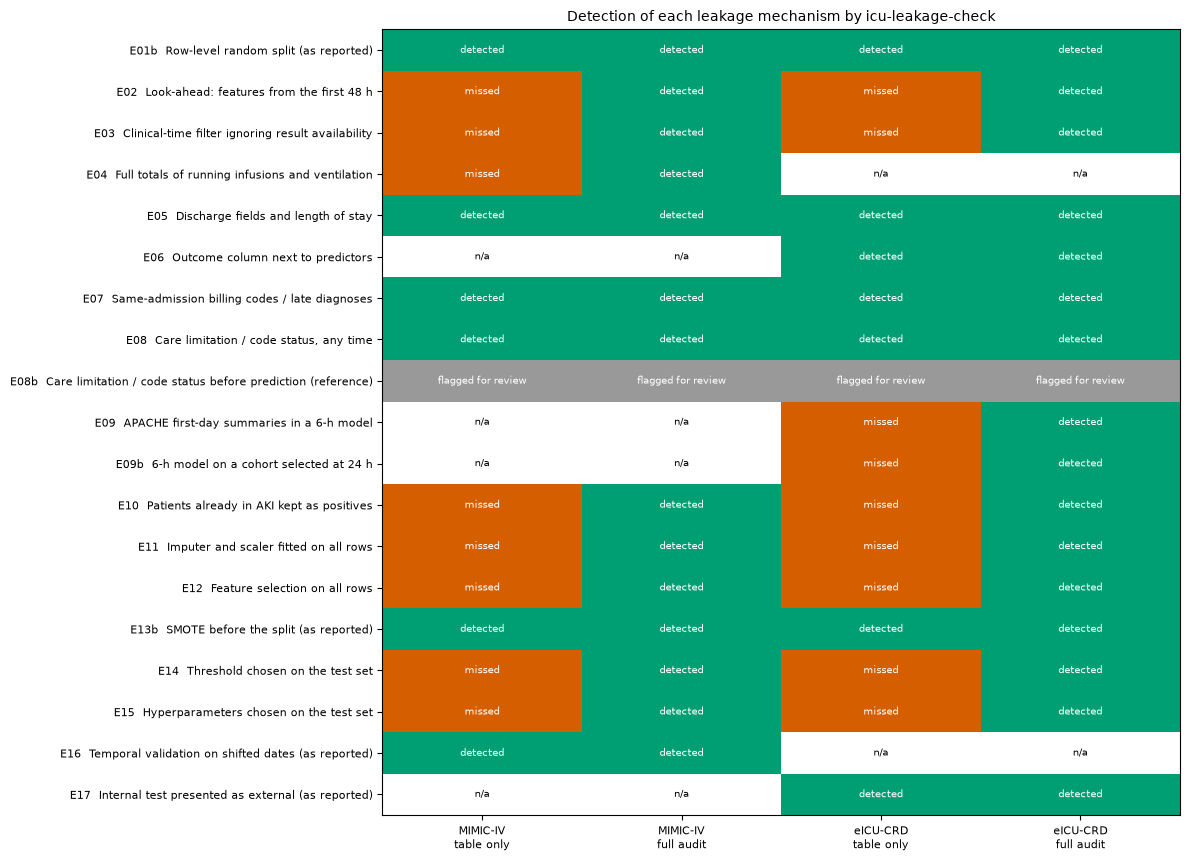

,database,mode,detected,mechanisms,share_detected
0,eicu,full,16,16,1.0
1,eicu,table,7,16,0.4375
2,mimic-iv,full,14,14,1.0
3,mimic-iv,table,6,14,0.428571


In [11]:
REFERENCE = {"E08b"}  # legitimate when documented before the prediction; a flag here is a prompt for review, not a leak
mechs = [m for m in MECH if m in set(detection["mechanism"])]
cols = [(db, mode) for db in DATABASES for mode in ("table", "full")]
grid = np.full((len(mechs), len(cols)), np.nan)
for i, m in enumerate(mechs):
    for j, (db, mode) in enumerate(cols):
        v = detection[(detection["mechanism"] == m) & (detection["database"] == db) & (detection["mode"] == mode)]["detected"]
        if len(v):
            grid[i, j] = (2.0 if bool(v.iloc[0]) else 0.0) if m in REFERENCE else float(bool(v.iloc[0]))
fig, ax = plt.subplots(figsize=(2.0 * len(cols) + 4, 0.38 * len(mechs) + 1.5))
cmap = matplotlib.colors.ListedColormap(["#D55E00", "#009E73", "#999999"])
masked = np.ma.masked_invalid(grid)
ax.imshow(masked, cmap=cmap, vmin=-0.5, vmax=2.5, aspect="auto")
for i in range(len(mechs)):
    for j in range(len(cols)):
        txt = "n/a" if np.isnan(grid[i, j]) else {0.0: "missed", 1.0: "detected", 2.0: "flagged for review"}[grid[i, j]]
        ax.text(j, i, txt, ha="center", va="center", fontsize=7, color="black" if np.isnan(grid[i, j]) else "white")
ax.set_yticks(range(len(mechs)))
ax.set_yticklabels([f"{m}  {MECH[m][0]}" for m in mechs], fontsize=8)
ax.set_xticks(range(len(cols)))
ax.set_xticklabels([f"{LABEL[db]}\n{'table only' if mode == 'table' else 'full audit'}" for db, mode in cols], fontsize=8)
ax.set_title("Detection of each leakage mechanism by icu-leakage-check", fontsize=10)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_detection_matrix.png", dpi=300, bbox_inches="tight", metadata={"Software": None})
fig.savefig(FIG_DIR / "fig_detection_matrix.pdf", bbox_inches="tight", metadata={"CreationDate": None, "Producer": None, "Creator": None})
plt.show()

det_summary = (detection[~detection["mechanism"].isin({"E00"} | REFERENCE)].groupby(["database", "mode"])["detected"]
               .agg(detected="sum", mechanisms="size").reset_index())
det_summary["share_detected"] = det_summary["detected"] / det_summary["mechanisms"]
det_summary.to_csv(TABLES_DIR / "detection_summary.csv", index=False)
display(det_summary)

## 7. Key numbers and reproducibility manifest

The manifest hashes every result file and chains the digest to the Part 1 chain digest, so the two notebooks form one
verifiable record.

In [12]:
key = {}
for db in DATABASES:
    for task in TASKS:
        r = results[(results["database"] == db) & (results["task"] == task) & (results["metric"] == "auroc")]
        base = r[r["mechanism"] == "E00"].set_index("model")["clean"].round(4).to_dict()
        lk = r[r["mechanism"] != "E00"]
        top = lk.sort_values("difference", ascending=False).head(5)
        key[f"{LABEL[db]} | {TASK_DEF[task]['name']}"] = {
            "clean AUROC by model": base,
            "largest AUROC inflations": [f"{row.mechanism} {row.model}: {row.difference:+.3f} ({row.diff_lower:+.3f} to {row.diff_upper:+.3f}), {row.comparison}"
                                         for row in top.itertuples()],
            "paired comparisons with AUROC inflation (lower 95% bound above zero)": int(((lk["comparison"] == "paired") & (lk["diff_lower"] > 0)).sum()),
        }
for row in det_summary.itertuples():
    key[f"detection {LABEL[row.database]} {row.mode}"] = f"{int(row.detected)} of {int(row.mechanisms)} mechanisms"
(RESULTS_DIR / "key_numbers_part2.json").write_text(json.dumps(key, indent=2))
print(json.dumps(key, indent=2))


def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


files = []
for folder in (RESULTS_DIR, PRIVATE_DIR):
    for p in sorted(folder.rglob("*")):
        if p.is_file() and p.name != "manifest_part2.json":
            files.append({"file": str(p.relative_to(PART_DIR)).replace("\\", "/"), "bytes": p.stat().st_size, "sha256": sha256_file(p)})
chain = hashlib.sha256(part1_manifest["chain_sha256"].encode())
for f in sorted(files, key=lambda r: r["file"]):
    if f["file"].startswith("private_reports/") or f["file"].endswith("key_numbers_part2.json"):
        continue
    chain.update(f"{f['file']}:{f['sha256']}\n".encode())
chain.update(json.dumps(CONFIG, sort_keys=True).encode())
chain.update(json.dumps({k: v for k, v in ENV.items() if k not in ("run_started_utc", "platform")}, sort_keys=True).encode())
manifest = {"part": 2, "previous_chain_sha256": part1_manifest["chain_sha256"], "environment": ENV, "configuration": CONFIG,
            "files": files, "chain_sha256": chain.hexdigest(), "runtime_minutes": round((time.time() - RUN_START) / 60, 1)}
(PART_DIR / "manifest_part2.json").write_text(json.dumps(manifest, indent=2))
(RESULTS_DIR / "manifest_part2.json").write_text(json.dumps(manifest, indent=2))
print(f"\n{len(files)} files hashed; chain digest {manifest['chain_sha256']}; runtime {manifest['runtime_minutes']} min")

{
  "MIMIC-IV | In-hospital mortality": {
    "clean AUROC by model": {
      "logistic": 0.8676,
      "hgb": 0.8854
    },
    "largest AUROC inflations": [
      "E05 logistic: +0.130 (+0.120 to +0.141), paired",
      "E05 hgb: +0.113 (+0.103 to +0.122), paired",
      "E13b hgb: +0.106 (+0.097 to +0.116), as reported",
      "E07 logistic: +0.071 (+0.062 to +0.081), paired",
      "E07 hgb: +0.061 (+0.053 to +0.069), paired"
    ],
    "paired comparisons with AUROC inflation (lower 95% bound above zero)": 14
  },
  "MIMIC-IV | Prolonged ICU stay (> 4 days)": {
    "clean AUROC by model": {
      "logistic": 0.7721,
      "hgb": 0.7977
    },
    "largest AUROC inflations": [
      "E05 logistic: +0.228 (+0.218 to +0.239), paired",
      "E05 hgb: +0.202 (+0.193 to +0.212), paired",
      "E13b hgb: +0.125 (+0.114 to +0.135), as reported",
      "E02 hgb: +0.076 (+0.068 to +0.084), paired",
      "E02 logistic: +0.068 (+0.060 to +0.076), paired"
    ],
    "paired comparisons with

## What Part 3 builds on

* `results/tables/inflation_all.csv`: every mechanism, task, model and metric with paired or as-reported differences.
* `results/tables/table_inflation_<task>.csv`: formatted main tables.
* `results/tables/detection_matrix.csv` and `detection_summary.csv`: what the audit caught with the table only and with
  full provenance.
* `results/tables/threshold_effects.csv` and the corrected availability summaries from Part 1.

Part 3 audits the published literature: it codes MIMIC-IV and eICU-CRD prediction studies for these mechanisms, estimates
their prevalence, and combines prevalence with the inflation measured here to estimate how optimistic the reported
performance of the field is likely to be.